# Case Study 3: Data Validation Notebook
**Pure Insights Command Centre: report monitoring dataset**

Before building any dashboard, alert or cost query, I need to know what is wrong with the data and decide how each problem will be handled. This notebook does that. It produces:

- `data/pure_insights_clean.csv`: cleaned data with flag columns (no rows dropped)
- `data/dq_issues.csv`: the data-quality issue log that the dashboard's *Data Quality* page will show

**Principle:** flag, don't delete. A negative-credit row is still a real report that has an owner and users, so I exclude the bad *value* from cost maths and keep the row.

Cleaning rules live in `validation/cleaning.py` so the backend seeding step uses the identical logic.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path('..').resolve()))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from validation import cleaning as cl

pd.set_option('display.width', 140)
plt.rcParams.update({'figure.figsize': (7, 3.2), 'axes.spines.top': False, 'axes.spines.right': False})

raw = cl.load_raw('../data/pure_insights_raw.csv')
raw.head()

,report_id,report_name,owner_email,last_refresh_status,monthly_active_views,snowflake_credits_consumed,avg_load_time_sec,aws_hosting_cost_usd,query_count_last_30d,concurrent_user_peak
0,RPT_200,Analytics Dashboard 1,user_7@company.com,SUCCESS,186,857.88,44.8,75.51,12825,142
1,RPT_201,Analytics Dashboard 2,user_6@company.com,SUCCESS,784,886.19,12.3,254.10,2498,30
2,RPT_202,Analytics Dashboard 3,user_5@company.com,SUCCESS,1492,324.20,24.9,236.47,17906,131
3,RPT_203,Analytics Dashboard 4,nan,TIMED_OUT,706,74.59,17.8,164.00,5626,130
4,RPT_204,Analytics Dashboard 5,user_5@company.com,TIMED_OUT,875,165.99,53.4,204.73,19165,10


## 1. First look: shape and types

In [2]:
print(raw.shape)
raw.dtypes.to_frame('dtype').T

(2000, 10)


,report_id,report_name,owner_email,last_refresh_status,monthly_active_views,snowflake_credits_consumed,avg_load_time_sec,aws_hosting_cost_usd,query_count_last_30d,concurrent_user_peak
dtype,str,str,str,str,int64,float64,float64,float64,int64,int64


In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
monthly_active_views,2000.0,751.64,429.67,0.00,380.75,748.50,1121.50,1499.00
snowflake_credits_consumed,2000.0,603.10,351.77,-13.60,298.14,615.57,905.94,1199.97
avg_load_time_sec,2000.0,27.88,15.51,0.60,14.78,27.80,41.20,55.00
aws_hosting_cost_usd,2000.0,230.97,125.58,15.04,124.79,230.54,340.84,449.64
query_count_last_30d,2000.0,12594.58,7282.02,20.00,6103.25,12779.50,18900.00,24998.00
concurrent_user_peak,2000.0,74.86,43.23,1.00,36.00,76.00,112.25,149.00


Nothing is missing in the numeric columns, but the ranges already show two things worth checking: `snowflake_credits_consumed` has a **negative minimum**, and `avg_load_time_sec` goes up to **55 seconds**.

## 2. Structure: what is one row?

In [4]:
per_id = raw.groupby('report_id').size()
print('rows:', len(raw), '| unique report_id:', raw.report_id.nunique())
print('rows per report_id -> min/max:', per_id.min(), per_id.max())
print('fully identical rows:', raw.duplicated().sum())
print('report names per id (max):', raw.groupby('report_id').report_name.nunique().max())
print('distinct owners per report (min/median/max):',
      raw.groupby('report_id').owner_email.nunique().agg(['min','median','max']).tolist())

rows: 2000 | unique report_id: 100
rows per report_id -> min/max: 20 20
fully identical rows: 0
report names per id (max): 1
distinct owners per report (min/median/max): [7.0, 12.0, 14.0]


**Finding:** the file is not 2,000 reports. It is **100 reports x exactly 20 rows each**. No two rows are identical, and the numbers differ between rows of the same report, so these are not copy-paste duplicates. The owner also changes between rows of the same report (about 12 different owners per report).

**Assumption A1 (important):** there is no timestamp, so I treat each repeated row as a *snapshot* of the report and use file order as `snapshot_seq` (1 to 20). I'm not deleting them. If the business says they are true duplicates, deduplicating by `report_id` is a one-line change in `cleaning.py`.

**Assumption A2:** because owner changes between snapshots, "is this report orphaned?" is evaluated **per snapshot**, and I also report the share of snapshots each report spent without an owner.

## 3. Defect 1: orphaned reports (missing owner)

In [5]:
print(raw.owner_email.isin(['nan','ORPHANED_REPORT']).sum(), 'rows have no real owner')
raw.loc[raw.owner_email.isin(['nan','ORPHANED_REPORT']), 'owner_email'].value_counts()

245 rows have no real owner


owner_email
nan                128
ORPHANED_REPORT    117
Name: count, dtype: int64

Two different encodings of the same problem: the string `'nan'` (an empty value that got written out as text) and the explicit label `'ORPHANED_REPORT'`. If I only filtered one, I would undercount orphans. Both go into a single `is_orphaned` flag, and I keep `orphan_reason` so the source is traceable.

## 4. Defect 2: negative Snowflake credits

24 rows | range: -13.6 to -0.8


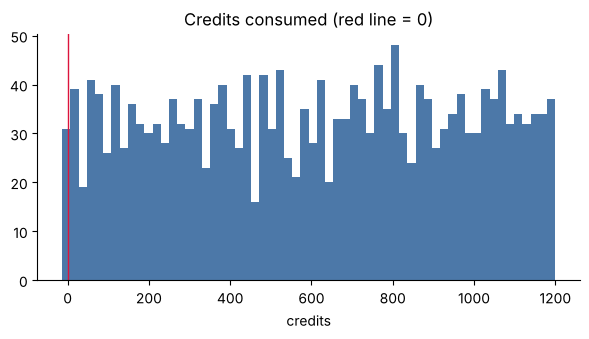

,report_id,report_name,owner_email,last_refresh_status,monthly_active_views,snowflake_credits_consumed,avg_load_time_sec,aws_hosting_cost_usd,query_count_last_30d,concurrent_user_peak
90,RPT_290,Analytics Dashboard 91,user_1@company.com,SUCCESS,239,-7.88,20.1,367.79,11173,88
195,RPT_295,Analytics Dashboard 96,user_1@company.com,SUCCESS,456,-9.20,24.6,133.46,10945,57
392,RPT_292,Analytics Dashboard 93,user_8@company.com,SUCCESS,434,-0.99,49.8,352.34,12282,37
462,RPT_262,Analytics Dashboard 63,user_12@company.com,SUCCESS,415,-8.95,1.3,437.02,20873,93
474,RPT_274,Analytics Dashboard 75,user_5@company.com,TIMED_OUT,617,-9.43,51.8,177.24,136,122


In [6]:
neg = raw[raw.snowflake_credits_consumed < 0]
print(len(neg), 'rows | range:', neg.snowflake_credits_consumed.min(), 'to', neg.snowflake_credits_consumed.max())
fig, ax = plt.subplots()
ax.hist(raw.snowflake_credits_consumed, bins=60, color='#4C78A8')
ax.axvline(0, color='crimson', lw=1)
ax.set_title('Credits consumed (red line = 0)'); ax.set_xlabel('credits')
plt.show()
neg.head()

Credits cannot be negative. The values are small (around -1 to -14) next to a typical value in the hundreds, so they look like adjustments or ingestion errors, not a different scale. I will **null the value** (`credits_clean`) and exclude it from cost sums. I will *not* take the absolute value, because that would invent spend that I cannot justify.

## 5. Defect 3: latency spikes

min/median/max: 0.6 27.8 55.0
> 15s: 1490 rows (74.5%)
> 30s: 910 rows (45.5%)
> 45s: 358 rows (17.9%)


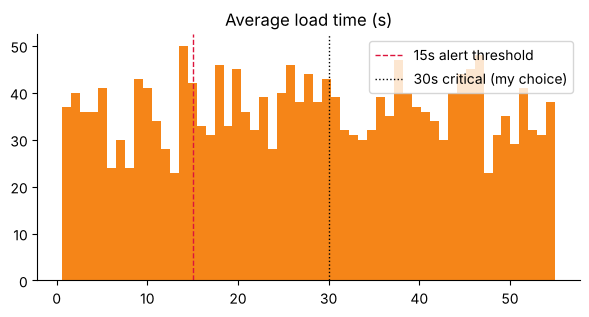

In [7]:
lat = raw.avg_load_time_sec
print('min/median/max:', lat.min(), lat.median(), lat.max())
for t in (15, 30, 45):
    print(f'> {t}s: {(lat>t).sum()} rows ({(lat>t).mean():.1%})')
fig, ax = plt.subplots()
ax.hist(lat, bins=55, color='#F58518')
ax.axvline(15, color='crimson', lw=1, ls='--', label='15s alert threshold')
ax.axvline(30, color='black', lw=1, ls=':', label='30s critical (my choice)')
ax.legend(); ax.set_title('Average load time (s)'); plt.show()

**This matters for the alerting design.** The load time is spread almost evenly from 1s to 55s, so a flat 15s rule fires on roughly **three-quarters of all rows**. An alert that fires that often is noise and people stop reading it. So:

- the brief's 15s rule becomes the **warning** tier
- I add a **critical** tier at 30s (my own choice, easy to change in `cleaning.py`)
- the alert engine will use a per-report **cooldown** so one slow report doesn't flood the feed

## 6. Defect 4: AWS cost vs. active users

In [8]:
num = ['monthly_active_views','snowflake_credits_consumed','avg_load_time_sec',
       'aws_hosting_cost_usd','query_count_last_30d','concurrent_user_peak']
corr = raw[num].corr().round(2)
corr

,monthly_active_views,snowflake_credits_consumed,avg_load_time_sec,aws_hosting_cost_usd,query_count_last_30d,concurrent_user_peak
monthly_active_views,1.00,0.05,0.02,-0.03,-0.00,-0.03
snowflake_credits_consumed,0.05,1.00,0.02,0.02,0.01,0.01
avg_load_time_sec,0.02,0.02,1.00,-0.01,0.01,-0.02
aws_hosting_cost_usd,-0.03,0.02,-0.01,1.00,-0.02,-0.02
query_count_last_30d,-0.00,0.01,0.01,-0.02,1.00,-0.01
concurrent_user_peak,-0.03,0.01,-0.02,-0.02,-0.01,1.00


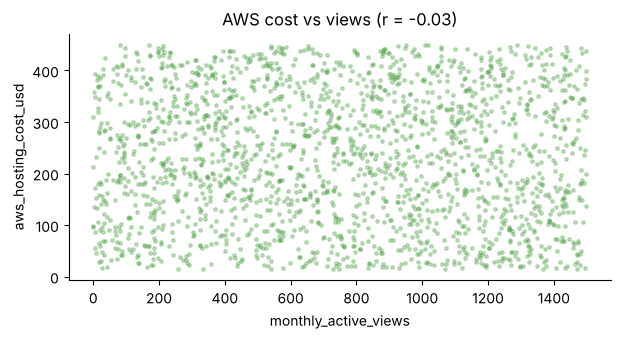

In [9]:
fig, ax = plt.subplots()
ax.scatter(raw.monthly_active_views, raw.aws_hosting_cost_usd, s=6, alpha=.35, color='#54A24B')
ax.set_xlabel('monthly_active_views'); ax.set_ylabel('aws_hosting_cost_usd')
ax.set_title(f"AWS cost vs views (r = {corr.loc['monthly_active_views','aws_hosting_cost_usd']})")
plt.show()

**Honest finding:** every pair of columns has a correlation close to zero. AWS cost does not rise with views, credits do not rise with query count, and slow reports do not cost more. That is exactly the "discrepancy between active users and AWS compute cost" the brief describes, but it also tells me this is **synthetic data with independent random columns**. I will not claim business relationships like "slow reports burn more credits" because the data does not support them.

What I *can* do usefully is rank by **cost per view** and flag the extreme cases for review.

In [10]:
df = cl.clean(raw)
top = df.nlargest(8, 'aws_cost_per_view')[['report_id','monthly_active_views','aws_hosting_cost_usd','aws_cost_per_view']]
print('median AWS cost per view: %.2f USD | 95th pct: %.2f USD' % (df.aws_cost_per_view.median(), df.aws_cost_per_view.quantile(.95)))
top

median AWS cost per view: 0.32 USD | 95th pct: 2.64 USD


,report_id,monthly_active_views,aws_hosting_cost_usd,aws_cost_per_view
401,RPT_201,2,359.15,179.575000
1578,RPT_278,1,135.45,135.450000
623,RPT_223,5,348.71,69.742000
1743,RPT_243,6,393.27,65.545000
667,RPT_267,10,381.41,38.141000
1353,RPT_253,5,172.43,34.486000
1804,RPT_204,15,388.38,25.892000
1971,RPT_271,9,231.22,25.691111


## 7. Other checks the brief did not list

In [11]:
print(raw.last_refresh_status.value_counts().to_frame('rows').assign(pct=lambda x: (x.rows/len(raw)*100).round(1)))
print()
print('zero-view rows:', (raw.monthly_active_views==0).sum())
print('peak concurrent users > monthly views:', (raw.concurrent_user_peak > raw.monthly_active_views).sum())

                     rows   pct
last_refresh_status            
SUCCESS              1336  66.8
FAILED                382  19.1
TIMED_OUT             182   9.1
UNKNOWN               100   5.0

zero-view rows: 4
peak concurrent users > monthly views: 93


- **UNKNOWN refresh status (100 rows):** the refresh outcome is not known, so it is neither success nor failure. It is its own state in the dashboard and gets no failure alert.
- **Zero views (4 rows):** cost per view would divide by zero, so per-view metrics are `NULL` for those rows.
- **Peak concurrent users above monthly views (93 rows):** you cannot have more people online at once than total views in the month, so these values look inconsistent. I flag them but keep the values.

## 8. Apply the cleaning rules and build the issue log

In [12]:
df = cl.clean(raw)
issues = cl.build_issue_log(raw, df)
issues

,issue,column,rows_affected,action,pct_of_rows
0,Orphaned report (owner 'nan'),owner_email,128,"Flag is_orphaned, keep row, show in Orphaned R...",6.4
1,Orphaned report ('ORPHANED_REPORT'),owner_email,117,Same flag as above; two encodings of the same ...,5.9
2,Negative Snowflake credits,snowflake_credits_consumed,24,"Keep row, null the value in credits_clean, exc...",1.2
3,Refresh status UNKNOWN,last_refresh_status,100,Own status; not counted as success or failure,5.0
4,Load time 15-30s (warning tier),avg_load_time_sec,580,"Alert, severity=warning, with per-report cooldown",29.0
5,Load time above 30s (critical),avg_load_time_sec,910,"Alert, severity=critical",45.5
6,Zero monthly views,monthly_active_views,4,Per-view metrics set to NULL (no divide-by-zero),0.2
7,Peak concurrent users > monthly views,concurrent_user_peak,93,Flag as suspicious; keep values,4.6
8,AWS cost per view above 95th percentile (> 2.6...,aws_hosting_cost_usd,100,Flag as cost-vs-usage mismatch for review,5.0
9,Report IDs repeated across rows,report_id,1900,Not deleted: treated as snapshots (snapshot_se...,95.0


In [13]:
# Sanity checks: the cleaning must not lose or invent rows
assert len(df) == len(raw)
assert df.credits_clean.min() >= 0
assert df.is_orphaned.sum() == raw.owner_email.isin(['nan','ORPHANED_REPORT']).sum()
assert df.owner_email_clean.isna().sum() == df.is_orphaned.sum()
assert df.aws_cost_per_view.notna().sum() == (raw.monthly_active_views > 0).sum()
print('all checks passed')

all checks passed


## 9. What this means for the alert design

In [14]:
rule_warn = (df.latency_severity != 'ok').sum()
rule_crit = (df.latency_severity == 'critical').sum()
rule_fail = df.refresh_failed.sum()
summary = pd.DataFrame({
    'rule': ['latency > 15s', 'latency > 30s (critical)', 'refresh FAILED/TIMED_OUT', 'any of the above'],
    'rows': [rule_warn, rule_crit, rule_fail, ((df.latency_severity != 'ok') | df.refresh_failed).sum()],
})
summary['pct_of_rows'] = (summary.rows / len(df) * 100).round(1)
summary

,rule,rows,pct_of_rows
0,latency > 15s,1490,74.5
1,latency > 30s (critical),910,45.5
2,refresh FAILED/TIMED_OUT,564,28.2
3,any of the above,1636,81.8


Even with a critical tier, a naive rule fires on most rows. The backend alert engine needs severity tiers and a cooldown, which is why those are in the design.

## 10. Share of snapshots without an owner, per report

In [15]:
orph_by_report = df.groupby('report_id').is_orphaned.mean().sort_values(ascending=False)
print(orph_by_report.describe().round(3))
orph_by_report.head(10).to_frame('share_orphaned')

count    100.000
mean       0.123
std        0.076
min        0.000
25%        0.050
50%        0.100
75%        0.150
max        0.350
Name: is_orphaned, dtype: float64


,share_orphaned
report_id,
RPT_222,0.35
RPT_204,0.30
RPT_220,0.30
RPT_239,0.30
RPT_265,0.25
RPT_243,0.25
RPT_283,0.25
RPT_294,0.25
RPT_237,0.25


No report is *always* orphaned. The worst reports are missing an owner in about a third of their snapshots. For the dashboard, a report is shown as **currently orphaned** if its latest snapshot (highest `snapshot_seq`) has no owner. The share above is shown as supporting context.

## 11. Save outputs

In [16]:
df.to_csv('../data/pure_insights_clean.csv', index=False)
issues.to_csv('../data/dq_issues.csv', index=False)
print('saved', df.shape, 'and', issues.shape)

saved (2000, 23) and (10, 5)


## Summary of decisions

| Decision | Choice | Why |
|---|---|---|
| Repeated `report_id` | Keep as snapshots (`snapshot_seq`) | Rows differ, no timestamp; deleting would discard 95% of the data |
| Orphans | One `is_orphaned` flag over both encodings | Avoids undercounting |
| Negative credits | Keep row, null the value | Cannot justify abs() or imputation |
| UNKNOWN status | Separate state | Not evidence of success or failure |
| Latency alerts | Warning > 15s, critical > 30s, cooldown | Flat 15s rule fires on about 75% of rows |
| Zero views | Per-view metrics NULL | No divide-by-zero |
| Insights | Rank by cost per view | Columns are uncorrelated, so no causal claims |

**Handoff:** the SQL suite loads `pure_insights_clean.csv` (using `credits_clean`, never the raw credits column) and the backend seeds its database from the same file.